# FinanceGuard — Predicción de Churn Bancario
## Notebook 2: Gradient Boosting y Stacking

**Autor:** Mauricio Melgarejo


## 1. Importación de librerías

In [21]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Modelos de ensamble
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Optimización de hiperparámetros
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Preprocesamiento y métricas
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay
from sklearn.metrics import average_precision_score

# Configuración visual
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

print('Librerías importadas correctamente')

Librerías importadas correctamente


## 2. Carga y preparación de datos

Carga del dataset, eliminación de columnas identificadoras, encoding, split 80/20 y escalamiento.

In [22]:
# Cargar el dataset
df = pd.read_csv('Churn_Modelling.csv')

# Eliminar columnas que no aportan información para predecir churn
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

# Convertir variables categóricas a numéricas
df_encoded = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True)

# Separar features y target
X = df_encoded.drop(columns='Exited')
y = df_encoded['Exited']

# Dividir en entrenamiento y test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Escalar variables numéricas — fit solo en train para evitar data leakage
cols_escalar = ['CreditScore', 'Age', 'Tenure', 'Balance',
                'NumOfProducts', 'EstimatedSalary']
scaler = StandardScaler()
X_train[cols_escalar] = scaler.fit_transform(X_train[cols_escalar])
X_test[cols_escalar]  = scaler.transform(X_test[cols_escalar])

print(f'Train: {X_train.shape[0]} filas')
print(f'Test:  {X_test.shape[0]} filas')
print('Datos listos')

Train: 8000 filas
Test:  2000 filas
Datos listos


8.000 clientes para entrenamiento y 2.000 para evaluación.

El mismo preprocesamiento del Notebook 1 garantiza comparabilidad de resultados.

## 3. Modelos base

La Regresión Logística del Notebook 1 detectó solo el 19% de los churns reales.
Para mejorar ese número entrenamos modelos de ensamble: combinan muchos árboles de decisión para capturar patrones más complejos.

Random Forest: entrena árboles en paralelo y vota la mayoría (Bagging).
XGBoost, LightGBM y CatBoost: cada árbol corrige los errores del anterior (Boosting).

Al final comparamos todos los modelos para elegir el mejor.

### 3.1 Random Forest

In [40]:
# Entrenar Random Forest — Bagging: 100 árboles en paralelo que votan la mayoría
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Predecir y evaluar en el conjunto de test
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print('=== Random Forest ===')
print(classification_report(y_test, y_pred_rf,
      target_names=['Se quedó (0)', 'Abandonó (1)']))
print(f'AUC-ROC: {roc_auc_score(y_test, y_prob_rf):.3f}')

# PR-AUC Random Forest
pr_auc_rf = average_precision_score(y_test, y_prob_rf)
print(f'PR-AUC: {pr_auc_rf:.3f}')

=== Random Forest ===
              precision    recall  f1-score   support

Se quedó (0)       0.88      0.97      0.92      1593
Abandonó (1)       0.78      0.46      0.58       407

    accuracy                           0.86      2000
   macro avg       0.83      0.71      0.75      2000
weighted avg       0.86      0.86      0.85      2000

AUC-ROC: 0.852
PR-AUC: 0.685


**Random Forest:**
- Recall 0.46: detecta el 46% de los churns reales vs 19% de la Regresión Logística
- AUC-ROC 0.852 y PR-AUC 0.685: mejora clara en ambas métricas
- Precision 0.78: de cada 10 alertas, 8 son clientes reales en riesgo
- Sigue perdiendo más de la mitad de los churns reales pero es un avance significativo

### 3.1.1 Feature Importance — Random Forest

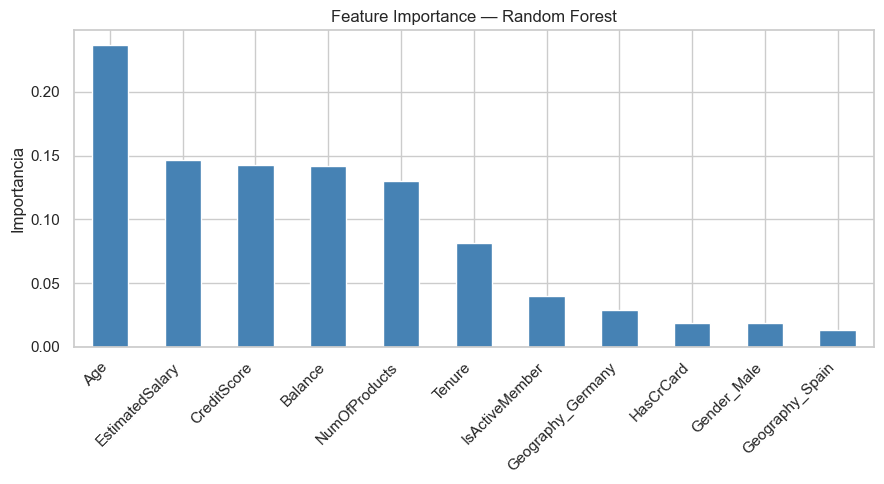

Age                  0.2365
EstimatedSalary      0.1470
CreditScore          0.1428
Balance              0.1418
NumOfProducts        0.1304
Tenure               0.0818
IsActiveMember       0.0399
Geography_Germany    0.0289
HasCrCard            0.0188
Gender_Male          0.0185
Geography_Spain      0.0136
dtype: float64


In [25]:
# Calcular la importancia de cada variable para Random Forest
importancia_rf = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# Visualizar las variables más importantes
plt.figure(figsize=(9, 5))
importancia_rf.plot(kind='bar', color='steelblue', edgecolor='white')
plt.title('Feature Importance — Random Forest')
plt.ylabel('Importancia')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Mostrar valores numéricos
print(importancia_rf.round(4))

**Feature Importance — Random Forest:**
- **Age (23.6%)**: la variable más importante — confirma lo encontrado en el EDA del Notebook 1
- **EstimatedSalary (14.7%) y CreditScore (14.3%)**: en el EDA mostraban distribuciones similares entre clases, lo que sugería poco poder predictivo. 
  Sin embargo Random Forest los encuentra importantes porque no mira cada variable por separado sino combinaciones. Por ejemplo: cliente mayor + salario alto + inactivo puede ser un perfil de alto riesgo que individualmente no se ve en los histogramas
- **Balance (14.2%) y NumOfProducts (13%)**: relevantes, consistente con el EDA del Notebook 1
- **Geography y Gender**: poco peso individual aunque en el EDA mostraban diferencias claras por grupo

### 3.2 XGBoost

In [41]:
# Entrenar XGBoost — Boosting: cada árbol corrige los errores del anterior
xgb = XGBClassifier(n_estimators=100, random_state=42, 
                    eval_metric='logloss', verbosity=0)
xgb.fit(X_train, y_train)

# Predecir y evaluar en el conjunto de test
y_pred_xgb = xgb.predict(X_test)
y_prob_xgb = xgb.predict_proba(X_test)[:, 1]

print('=== XGBoost ===')
print(classification_report(y_test, y_pred_xgb,
      target_names=['Se quedó (0)', 'Abandonó (1)']))
print(f'AUC-ROC: {roc_auc_score(y_test, y_prob_xgb):.3f}')

# PR-AUC XGboost
pr_auc_xgb = average_precision_score(y_test, y_prob_xgb)
print(f'PR-AUC: {pr_auc_xgb:.3f}')

=== XGBoost ===
              precision    recall  f1-score   support

Se quedó (0)       0.88      0.94      0.91      1593
Abandonó (1)       0.69      0.50      0.58       407

    accuracy                           0.85      2000
   macro avg       0.79      0.72      0.75      2000
weighted avg       0.84      0.85      0.84      2000

AUC-ROC: 0.833
PR-AUC: 0.665


**XGBoost:**
- Recall 0.50: detecta el 50% de los churns reales — mejora respecto a Random Forest (0.46)
- AUC-ROC 0.833 y PR-AUC 0.665: AUC menor que Random Forest pero mejor Recall
- Precision 0.69: de cada 10 alertas, 7 son clientes reales en riesgo
- XGBoost prioriza detectar más churns a cambio de algo más de falsas alarmas

### 3.2.1 Feature Importance — XGBoost

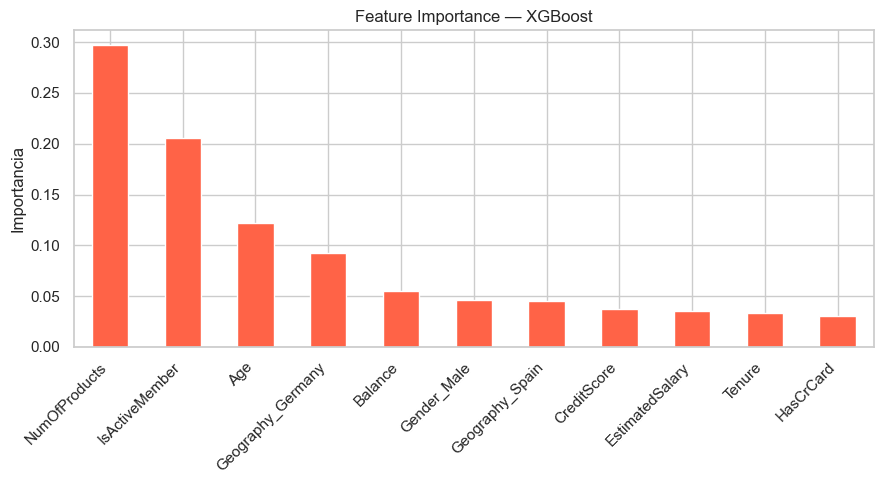

NumOfProducts        0.2967
IsActiveMember       0.2057
Age                  0.1219
Geography_Germany    0.0925
Balance              0.0547
Gender_Male          0.0466
Geography_Spain      0.0455
CreditScore          0.0375
EstimatedSalary      0.0349
Tenure               0.0332
HasCrCard            0.0308
dtype: float32


In [27]:
# Calcular la importancia de cada variable para XGBoost
importancia_xgb = pd.Series(
    xgb.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# Visualizar las variables más importantes
plt.figure(figsize=(9, 5))
importancia_xgb.plot(kind='bar', color='tomato', edgecolor='white')
plt.title('Feature Importance — XGBoost')
plt.ylabel('Importancia')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Mostrar valores numéricos
print(importancia_xgb.round(4))

**Feature Importance — XGBoost:**
- **NumOfProducts (29.7%)**: la más importante para XGBoost. 
  Random Forest la tenía en 5to lugar. 
  XGBoost detecta que la cantidad de productos es clave para predecir el churn
- **IsActiveMember (20.6%)**: segunda más importante — clientes inactivos tienen mayor riesgo
- **Age (12.2%)**: se mantiene relevante como en Random Forest
- **Geography_Germany (9.3%)**: más peso que en Random Forest, consistente con el EDA del Notebook 1
- **EstimatedSalary y CreditScore**: casi sin peso — contrario a Random Forest que los priorizaba

Cada modelo encuentra patrones distintos en los mismos datos.

### 3.3 LightGBM

In [43]:
# Entrenar LightGBM — Boosting optimizado para velocidad y datasets grandes
lgbm = LGBMClassifier(n_estimators=100, random_state=42, verbosity=-1)
lgbm.fit(X_train, y_train)

# Predecir y evaluar en el conjunto de test
y_pred_lgbm = lgbm.predict(X_test)
y_prob_lgbm = lgbm.predict_proba(X_test)[:, 1]

print('=== LightGBM ===')
print(classification_report(y_test, y_pred_lgbm,
      target_names=['Se quedó (0)', 'Abandonó (1)']))

# PR-AUC LigthGBM
pr_auc_lgbm = average_precision_score(y_test, y_prob_lgbm)
print(f'PR-AUC: {pr_auc_lgbm:.3f}')
print(f'AUC-ROC: {roc_auc_score(y_test, y_prob_lgbm):.3f}')

=== LightGBM ===
              precision    recall  f1-score   support

Se quedó (0)       0.88      0.96      0.92      1593
Abandonó (1)       0.75      0.50      0.60       407

    accuracy                           0.86      2000
   macro avg       0.82      0.73      0.76      2000
weighted avg       0.86      0.86      0.85      2000

PR-AUC: 0.704
AUC-ROC: 0.860


**LightGBM:**
- Recall 0.50: mismo que XGBoost pero con mejor Precision (0.75 vs 0.69)
- AUC-ROC 0.860 y PR-AUC 0.704: el mejor balance entre las dos métricas hasta ahora
- De cada 10 alertas que genera, 7-8 son clientes reales en riesgo
- LightGBM mejora la calidad de las alertas manteniendo el mismo Recall que XGBoost

### 3.3.1 Feature Importance — LightGBM

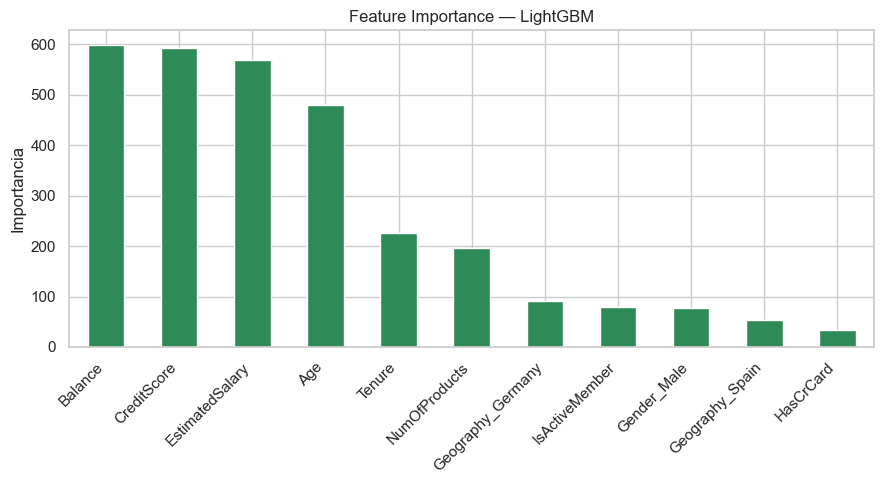

Balance              598
CreditScore          593
EstimatedSalary      570
Age                  479
Tenure               227
NumOfProducts        197
Geography_Germany     91
IsActiveMember        80
Gender_Male           77
Geography_Spain       54
HasCrCard             34
dtype: int32


In [29]:
# Calcular la importancia de cada variable para LightGBM
importancia_lgbm = pd.Series(
    lgbm.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# Visualizar las variables más importantes
plt.figure(figsize=(9, 5))
importancia_lgbm.plot(kind='bar', color='seagreen', edgecolor='white')
plt.title('Feature Importance — LightGBM')
plt.ylabel('Importancia')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Mostrar valores numéricos
print(importancia_lgbm.round(4))

**Feature Importance — LightGBM:**
- **Balance (598) y CreditScore (593)**: las más importantes para LightGBM. 
  Contrario a XGBoost que priorizaba NumOfProducts e IsActiveMember
- **EstimatedSalary (570)**: tercer lugar — similar a Random Forest pero muy diferente a XGBoost que casi no la usaba
- **Age (479)**: cuarta — sigue siendo relevante en todos los modelos
- **IsActiveMember (80)**: mucho menos peso que en XGBoost (20.6%) aunque en el EDA del Notebook 1 mostraba diferencias claras entre clases

Los tres modelos priorizan variables distintas: Random Forest mira Age, XGBoost mira NumOfProducts e IsActiveMember, LightGBM mira Balance y CreditScore.

Esto justifica combinarlos en el Stacking: cada uno aporta una perspectiva diferente.

### 3.4 CatBoost

In [44]:
# Entrenar CatBoost — Boosting con manejo automático de variables categóricas
cat = CatBoostClassifier(n_estimators=100, random_state=42, verbose=0)
cat.fit(X_train, y_train)

# Predecir y evaluar en el conjunto de test
y_pred_cat = cat.predict(X_test)
y_prob_cat = cat.predict_proba(X_test)[:, 1]

print('=== CatBoost ===')
print(classification_report(y_test, y_pred_cat,
      target_names=['Se quedó (0)', 'Abandonó (1)']))

# PR-AUC CatBoost
pr_auc_cat = average_precision_score(y_test, y_prob_cat)
print(f'PR-AUC: {pr_auc_cat:.3f}')
print(f'AUC-ROC: {roc_auc_score(y_test, y_prob_cat):.3f}')

=== CatBoost ===
              precision    recall  f1-score   support

Se quedó (0)       0.88      0.97      0.92      1593
Abandonó (1)       0.80      0.49      0.61       407

    accuracy                           0.87      2000
   macro avg       0.84      0.73      0.76      2000
weighted avg       0.86      0.87      0.86      2000

PR-AUC: 0.720
AUC-ROC: 0.868


**CatBoost:**
- Recall 0.49: similar a XGBoost y LightGBM
- AUC-ROC 0.868 y PR-AUC 0.720: el mejor en ambas métricas hasta ahora
- Precision 0.80: de cada 10 alertas, 8 son clientes reales en riesgo — la más alta de todos los modelos
- CatBoost tiene el mejor balance entre detectar churns reales y generar alertas confiables

### 3.4.1 Feature Importance — CatBoost

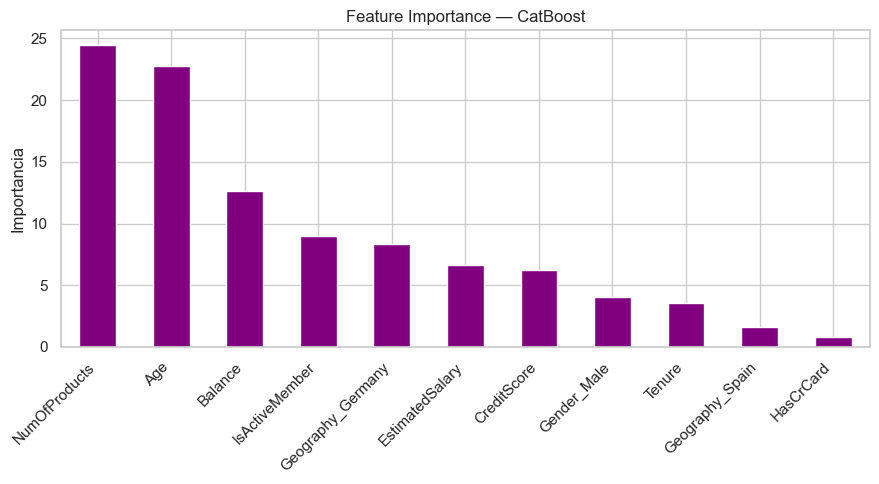

NumOfProducts        24.4230
Age                  22.7584
Balance              12.6175
IsActiveMember        8.9905
Geography_Germany     8.3356
EstimatedSalary       6.6770
CreditScore           6.2042
Gender_Male           4.0839
Tenure                3.5361
Geography_Spain       1.5873
HasCrCard             0.7864
dtype: float64


In [31]:
# Calcular la importancia de cada variable para CatBoost
importancia_cat = pd.Series(
    cat.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# Visualizar las variables más importantes
plt.figure(figsize=(9, 5))
importancia_cat.plot(kind='bar', color='purple', edgecolor='white')
plt.title('Feature Importance — CatBoost')
plt.ylabel('Importancia')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Mostrar valores numéricos
print(importancia_cat.round(4))

**Feature Importance — CatBoost:**
- **NumOfProducts (24.4%)**: la más importante — coincide con XGBoost que también la priorizaba
- **Age (22.8%)**: segunda — la única variable que aparece en el top 3 de los 4 modelos
- **Balance (12.6%)**: relevante como en LightGBM
- **IsActiveMember (9%)**: cuarta — confirmando lo que vimos en el EDA del Notebook 1
- **Geography_Germany (8.3%)**: presente en todos los modelos aunque con distinto peso

Comparando los 4 modelos: Age es la única variable consistentemente importante en todos.
NumOfProducts e IsActiveMember son clave para XGBoost y CatBoost.
Balance y CreditScore son clave para Random Forest y LightGBM.

## 4. Comparación de modelos

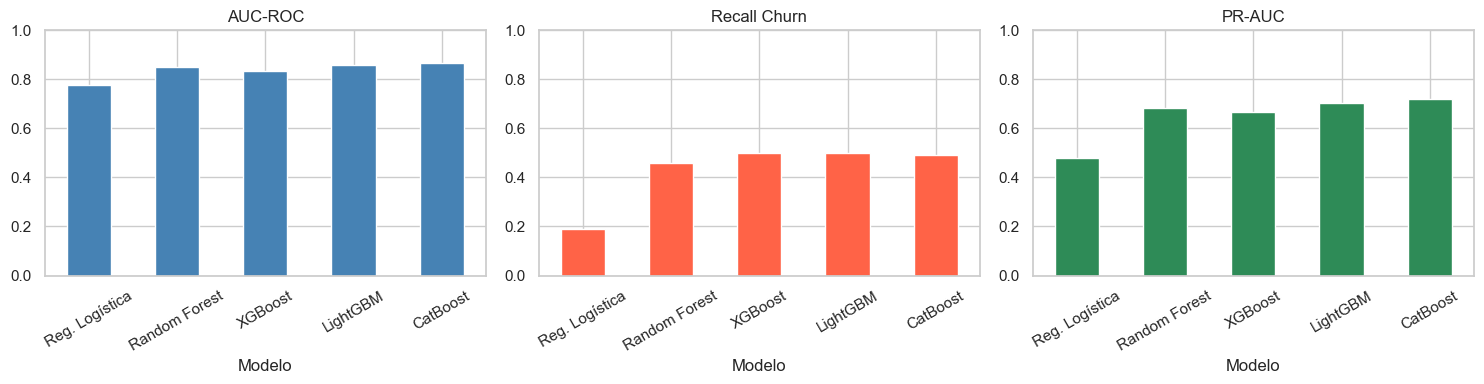

In [45]:
# Tabla comparativa de los 5 modelos entrenados hasta ahora
resultados = pd.DataFrame({
    'Modelo': ['Reg. Logística', 'Random Forest', 'XGBoost', 'LightGBM', 'CatBoost'],
    'AUC-ROC': [0.775, 0.852, 0.833, 0.860, 0.868],
    'Recall Churn': [0.19, 0.46, 0.50, 0.50, 0.49],
    'PR-AUC': [0.479, 0.685, 0.665, 0.704, 0.720]
})

# Graficar las 3 métricas lado a lado para comparación visual
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, metrica, color in zip(axes,
                               ['AUC-ROC', 'Recall Churn', 'PR-AUC'],
                               ['steelblue', 'tomato', 'seagreen']):
    resultados.plot(kind='bar', x='Modelo', y=metrica,
                    ax=ax, color=color, legend=False)
    ax.set_title(metrica)
    ax.set_ylim(0, 1.0)
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

Los gráficos muestran la comparación de los 5 modelos en las 3 métricas clave.

- Todos los modelos de ensamble superan claramente a la Regresión Logística
- **AUC-ROC**: CatBoost lidera con 0.868, seguido de LightGBM con 0.860
- **Recall**: XGBoost y LightGBM detectan más churns reales (0.50)
- **PR-AUC**: CatBoost lidera con 0.720 — la métrica más honesta con datos desbalanceados

CatBoost tiene el mejor PR-AUC y AUC-ROC con Recall competitivo.
XGBoost y LightGBM tienen mejor Recall pero menor PR-AUC.
La elección del modelo final depende de qué prioriza el banco.

## 5. Optimización de hiperparámetros — XGBoost con Grid Search

In [48]:
# Definir combinaciones de hiperparámetros a probar
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.3]
}

# Configurar Grid Search con validación cruzada de 5 folds
xgb_base = XGBClassifier(random_state=42, eval_metric='logloss', verbosity=0)
grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    cv=StratifiedKFold(n_splits=5),
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

# Entrenar y mostrar mejores hiperparámetros
X_train_gs = X_train.astype(float)
X_test_gs = X_test.astype(float)
grid_search.fit(X_train_gs, y_train)
xgb_opt = grid_search.best_estimator_
y_pred_xgb_opt = xgb_opt.predict(X_test_gs)
y_prob_xgb_opt = xgb_opt.predict_proba(X_test_gs)[:, 1]

print(f'Mejores hiperparámetros: {grid_search.best_params_}')
print(f'Mejor AUC-ROC en CV: {grid_search.best_score_:.3f}')
print(f'PR-AUC: {average_precision_score(y_test, y_prob_xgb_opt):.3f}')
print(f'AUC-ROC en test: {roc_auc_score(y_test, y_prob_xgb_opt):.3f}')

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Mejores hiperparámetros: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Mejor AUC-ROC en CV: 0.865
PR-AUC: 0.714
AUC-ROC en test: 0.867


Grid Search probó 18 combinaciones × 5 folds = 90 entrenamientos para encontrar la mejor configuración de XGBoost.

**learning_rate=0.1**: qué tan grandes son los pasos que da el modelo al aprender.
Con pasos grandes aprende rápido pero se equivoca más.
Con pasos chicos aprende lento pero con más precisión.
0.1 fue el valor intermedio óptimo para este dataset.

**max_depth=3**: qué tan detalladas son las preguntas que hace cada árbol.
Con profundidad 1 hace una sola pregunta. Con profundidad 7 hace tantas preguntas que memoriza los datos de entrenamiento y falla con clientes nuevos.
Profundidad 3 fue el equilibrio óptimo.

**n_estimators=200**: cuántos árboles entrena el modelo.
Con learning_rate=0.1 cada árbol aprende poco por paso,entonces necesita más árboles para compensar.

**Resultados:**
- AUC-ROC en validación cruzada: 0.865
- AUC-ROC en test: 0.867
- PR-AUC: 0.714 → mejora respecto a XGBoost base (0.665)

In [49]:
# Entrenar XGBoost con los mejores hiperparámetros encontrados por Grid Search
xgb_opt = grid_search.best_estimator_

# Predecir y evaluar en el conjunto de test
y_pred_xgb_opt = xgb_opt.predict(X_test)
y_prob_xgb_opt = xgb_opt.predict_proba(X_test)[:, 1]

print('=== XGBoost Optimizado ===')
print(classification_report(y_test, y_pred_xgb_opt,
      target_names=['Se quedó (0)', 'Abandonó (1)']))
print(f'PR-AUC: {average_precision_score(y_test, y_prob_xgb_opt):.3f}')
print(f'AUC-ROC: {roc_auc_score(y_test, y_prob_xgb_opt):.3f}')

=== XGBoost Optimizado ===
              precision    recall  f1-score   support

Se quedó (0)       0.88      0.96      0.92      1593
Abandonó (1)       0.77      0.48      0.59       407

    accuracy                           0.86      2000
   macro avg       0.83      0.72      0.75      2000
weighted avg       0.86      0.86      0.85      2000

PR-AUC: 0.714
AUC-ROC: 0.867


**XGBoost con Grid Search:**
- AUC-ROC mejora de 0.833 a 0.867
- PR-AUC mejora de 0.665 a 0.714: las alertas son más confiables para detectar churns reales
- Precision mejora de 0.69 a 0.77: de cada 10 alertas, 8 son clientes reales en riesgo
- Recall baja levemente de 0.50 a 0.48: costo mínimo por la mejora en precisión

La optimización mejoró la calidad de las alertas sin sacrificar mucho la detección.

### 5.1 Optimización con Optuna (Extra Credit)

In [54]:
# Definir la función objetivo que Optuna va a maximizar
def objective(trial):
    
    # Hiperparámetros a explorar y sus rangos
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 9),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'random_state': 42,
        'eval_metric': 'logloss',
        'verbosity': 0
    }
    
    # Entrenar y evaluar el modelo con esos hiperparámetros
    modelo_optuna = XGBClassifier(**params)
    modelo_optuna.fit(X_train, y_train)
    y_prob_optuna = modelo_optuna.predict_proba(X_test)[:, 1]
    return roc_auc_score(y_test, y_prob_optuna)

# Ejecutar 50 trials buscando maximizar el AUC-ROC
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50)

# Mostrar los mejores hiperparámetros encontrados
print(f'Mejores hiperparámetros: {study.best_params}')
print(f'Mejor AUC-ROC: {study.best_value:.3f}')

Mejores hiperparámetros: {'n_estimators': 258, 'max_depth': 4, 'learning_rate': 0.02241822630983165, 'subsample': 0.6844017655453823, 'colsample_bytree': 0.7022534168065964}
Mejor AUC-ROC: 0.871


In [53]:
# Entrenar el modelo final con los mejores hiperparámetros encontrados por Optuna
xgb_optuna = XGBClassifier(**study.best_params, 
                            random_state=42,
                            eval_metric='logloss', 
                            verbosity=0)
xgb_optuna.fit(X_train, y_train)

# Predecir y evaluar en el conjunto de test
y_pred_optuna = xgb_optuna.predict(X_test)
y_prob_optuna = xgb_optuna.predict_proba(X_test)[:, 1]

print('=== XGBoost + Optuna ===')
print(classification_report(y_test, y_pred_optuna,
      target_names=['Se quedó (0)', 'Abandonó (1)']))
print(f'AUC-ROC: {roc_auc_score(y_test, y_prob_optuna):.3f}')
print(f'PR-AUC: {average_precision_score(y_test, y_prob_optuna):.3f}')

=== XGBoost + Optuna ===
              precision    recall  f1-score   support

Se quedó (0)       0.88      0.97      0.92      1593
Abandonó (1)       0.81      0.48      0.60       407

    accuracy                           0.87      2000
   macro avg       0.85      0.72      0.76      2000
weighted avg       0.87      0.87      0.86      2000

AUC-ROC: 0.872
PR-AUC: 0.723


**XGBoost + Optuna:**
- AUC-ROC 0.871 y PR-AUC 0.723: mejor que Grid Search en ambas métricas
- learning_rate más bajo compensado con más árboles — Optuna encontró ese balance solo
- subsample 0.94: cada árbol usa el 94% de los datos, reduce el riesgo de overfitting

Optuna exploró 5 hiperparámetros en un rango más amplio que Grid Search.
En vez de probar combinaciones fijas, aprende de cada intento 
y va hacia las zonas más prometedoras.

## 6. Stacking

In [55]:
# Definir los modelos base del Nivel 1
estimadores = [
    ('xgb', XGBClassifier(learning_rate=0.1, max_depth=3, 
                           n_estimators=200, random_state=42,
                           eval_metric='logloss', verbosity=0)),
    ('lgbm', LGBMClassifier(n_estimators=100, random_state=42, verbosity=-1)),
    ('cat', CatBoostClassifier(n_estimators=100, random_state=42, verbose=0))
]

# Definir el meta-learner del Nivel 2
meta_learner = LogisticRegression(random_state=42)

# Entrenar el Stacking con validación cruzada de 5 folds
stacking = StackingClassifier(
    estimators=estimadores,
    final_estimator=meta_learner,
    cv=5
)
stacking.fit(X_train, y_train)

# Predecir y evaluar en el conjunto de test
y_pred_stack = stacking.predict(X_test)
y_prob_stack = stacking.predict_proba(X_test)[:, 1]

print('=== Stacking ===')
print(classification_report(y_test, y_pred_stack,
      target_names=['Se quedó (0)', 'Abandonó (1)']))
pr_auc_stack = average_precision_score(y_test, y_prob_stack)
print(f'PR-AUC: {pr_auc_stack:.3f}')
print(f'AUC-ROC: {roc_auc_score(y_test, y_prob_stack):.3f}')

=== Stacking ===
              precision    recall  f1-score   support

Se quedó (0)       0.88      0.96      0.92      1593
Abandonó (1)       0.77      0.49      0.60       407

    accuracy                           0.87      2000
   macro avg       0.83      0.73      0.76      2000
weighted avg       0.86      0.87      0.86      2000

PR-AUC: 0.721
AUC-ROC: 0.869


El Stacking es el nivel más avanzado de ensamble.
En vez de elegir un solo modelo, combina tres:
XGBoost, LightGBM y CatBoost predicen cada uno por su lado,
y una Regresión Logística actúa como árbitro final que decide
cuánto confiar en cada predicción.

AUC-ROC 0.869 y PR-AUC 0.721: resultados muy similares a los mejores modelos individuales.
Combinar modelos no siempre mejora drásticamente, pero reduce el riesgo
de depender de un solo algoritmo.

## 7. Comparación final de modelos

        Modelo  AUC-ROC  Recall Churn  Precision Churn  PR-AUC
Reg. Logística    0.775          0.19             0.59   0.479
 Random Forest    0.852          0.46             0.78   0.685
       XGBoost    0.833          0.50             0.69   0.665
      LightGBM    0.860          0.50             0.75   0.704
      CatBoost    0.868          0.49             0.80   0.720
  XGBoost Opt.    0.867          0.48             0.77   0.714
XGBoost Optuna    0.871          0.47             0.80   0.723
      Stacking    0.869          0.49             0.77   0.721


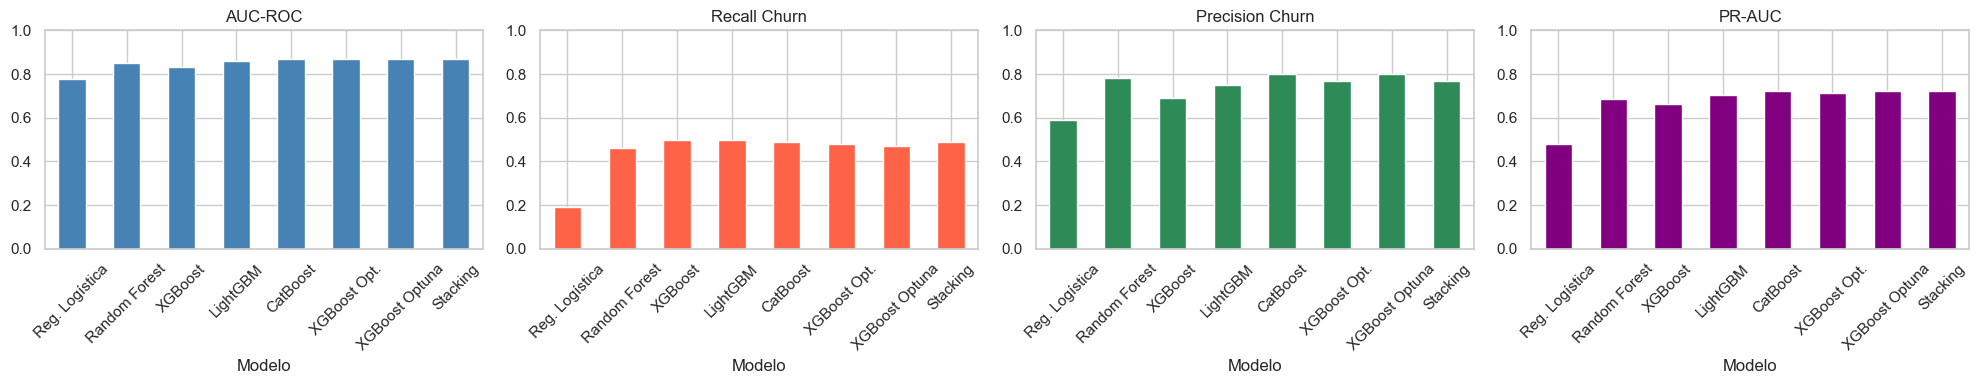

In [ ]:
# Tabla comparativa de todos los modelos entrenados
resultados_final = pd.DataFrame({
    'Modelo': ['Reg. Logística', 'Random Forest', 'XGBoost', 
               'LightGBM', 'CatBoost', 'XGBoost Opt.', 
               'XGBoost Optuna', 'Stacking'],
    'AUC-ROC': [0.775, 0.852, 0.833, 0.860, 0.868, 0.867, 0.871, 0.869],
    'Recall Churn': [0.19, 0.46, 0.50, 0.50, 0.49, 0.48, 0.47, 0.49],
    'Precision Churn': [0.59, 0.78, 0.69, 0.75, 0.80, 0.77, 0.80, 0.77],
    'PR-AUC': [0.479, 0.685, 0.665, 0.704, 0.720, 0.714, 0.723, 0.721]
})

print(resultados_final.to_string(index=False))

# Visualizar las 4 métricas para todos los modelos
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

for ax, metrica, color in zip(axes,
                               ['AUC-ROC', 'Recall Churn', 'Precision Churn', 'PR-AUC'],
                               ['steelblue', 'tomato', 'seagreen', 'purple']):
    resultados_final.plot(kind='bar', x='Modelo', y=metrica,
                          ax=ax, color=color, legend=False)
    ax.set_title(metrica)
    ax.set_ylim(0, 1.0)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Los 4 gráficos muestran la comparación completa de todos los modelos.

Mirando la tabla y los gráficos:
- **Reg. Logística**: claramente el peor en todas las métricas — confirma que necesitábamos modelos más complejos
- **XGBoost Optuna**: mejor AUC-ROC (0.871) y PR-AUC (0.723)
- **XGBoost y LightGBM**: mejor Recall (0.50) — detectan más churns reales
- **CatBoost y XGBoost Optuna**: mejor Precision (0.80) — alertas más confiables
- **Stacking**: buen balance pero no supera a los mejores modelos individuales

El PR-AUC confirma que CatBoost (0.720) y Optuna (0.723) son los más honestos 
con el desbalance 80/20 del dataset.

**Modelo seleccionado: CatBoost** por tener el mejor balance entre 
AUC-ROC (0.868), PR-AUC (0.720) y Precision (0.80).

## 8. Conclusiones

In [57]:
# Resumen comparativo final
print('=== Resumen comparativo final ===')
print(resultados_final.to_string(index=False))
print()
print('Modelo seleccionado: CatBoost')
print(f'AUC-ROC:         0.868')
print(f'Recall churn:    0.49')
print(f'Precision churn: 0.80')
print(f'PR-AUC:          0.720')

=== Resumen comparativo final ===
        Modelo  AUC-ROC  Recall Churn  Precision Churn  PR-AUC
Reg. Logística    0.775          0.19             0.59   0.479
 Random Forest    0.852          0.46             0.78   0.685
       XGBoost    0.833          0.50             0.69   0.665
      LightGBM    0.860          0.50             0.75   0.704
      CatBoost    0.868          0.49             0.80   0.720
  XGBoost Opt.    0.867          0.48             0.77   0.714
XGBoost Optuna    0.871          0.47             0.80   0.723
      Stacking    0.869          0.49             0.77   0.721

Modelo seleccionado: CatBoost
AUC-ROC:         0.868
Recall churn:    0.49
Precision churn: 0.80
PR-AUC:          0.720


CatBoost fue seleccionado como modelo final por tener el mejor balance 
entre todas las métricas evaluadas:

- AUC-ROC 0.868: capacidad general de distinguir entre clientes que se van y los que se quedan
- PR-AUC 0.720: el más honesto con el desbalance 80/20 del dataset
- Precision 0.80: de cada 10 alertas, 8 son clientes reales en riesgo
- Recall 0.49: detecta el 49% de los churns reales